# Bài tập nâng cao - Bước 3: Sai phân thường + mùa vụ
**Dataset 2:** AirPassengers (số hành khách hàng không theo tháng, 1949-01 đến 1960-12, 144 quan sát, chu kỳ mùa vụ s = 12)

**Mục tiêu:** tìm số lần sai phân thường **d** và sai phân mùa **D** để chuỗi trở nên **dừng**, chuẩn bị cho bước 4 (ACF/PACF) và mô hình SARIMA.

## 1. Thư viện
- `numpy`, `pandas`: xử lý dữ liệu và chuỗi thời gian.
- `matplotlib`: vẽ đồ thị.
- `adfuller` (statsmodels): kiểm định ADF để xem chuỗi dừng hay chưa.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 2. Hiểu hai loại sai phân bằng ví dụ nhỏ

- **Sai phân thường** `diff()`: lấy giá trị **trừ giá trị tháng trước**. Dùng để **bỏ xu hướng** (chuỗi tăng dần).
- **Sai phân mùa** `diff(12)`: lấy giá trị **trừ giá trị cùng tháng năm trước** (cách 12 bước). Dùng để **bỏ mùa vụ** (mẫu lặp lại mỗi năm).

Ví dụ thu nhỏ bên dưới có mẫu mùa lặp mỗi **4 bước** (thay cho 12) và tăng thêm 2 sau mỗi chu kỳ.

In [22]:
mau = pd.Series([10, 20, 30, 20,     # chu kỳ 1
                 12, 22, 32, 22,     # chu kỳ 2 (mỗi giá trị cao hơn 2)
                 14, 24, 34, 24])    # chu kỳ 3

print("Chuỗi ban đầu       :", mau.tolist())
print("Sai phân mùa (s=4)  :", mau.diff(4).dropna().tolist(), "-> mẫu mùa biến mất, chỉ còn mức tăng không đổi")
print("Thêm sai phân thường:", mau.diff(4).diff().dropna().tolist(), "-> hết cả xu hướng, còn toàn số 0")

Chuỗi ban đầu       : [10, 20, 30, 20, 12, 22, 32, 22, 14, 24, 34, 24]
Sai phân mùa (s=4)  : [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0] -> mẫu mùa biến mất, chỉ còn mức tăng không đổi
Thêm sai phân thường: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] -> hết cả xu hướng, còn toàn số 0


**Thử đổi số:** đổi mức tăng sau mỗi chu kỳ (từ 2 thành 5), hoặc đổi mẫu mùa, rồi chạy lại để thấy sai phân mùa luôn loại được mẫu lặp. Với AirPassengers, mẫu lặp mỗi **12 tháng** nên dùng `diff(12)`.

## 3. Đọc dữ liệu

- **Vì sao đổi cột ngày thành index thời gian?** Để pandas hiểu đây là chuỗi thời gian (thứ tự và khoảng cách giữa các điểm có ý nghĩa), từ đó mới dùng được `diff()`, `rolling()` và vẽ theo trục thời gian.
- `asfreq("MS")` khai báo dữ liệu theo tháng (ngày đầu mỗi tháng).
- `iloc[:, 0]` lấy cột đầu tiên, nên không phụ thuộc tên cột.
- **Lưu ý link:** link AirPassengers trong đề (`airlinepassengers.csv`) bị lỗi 404. File vẫn còn với tên có gạch ngang `airline-passengers.csv`.

In [23]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(URL, parse_dates=[0], index_col=0)
print(df.columns.tolist())              # kỳ vọng: ['Passengers']
ap = df.iloc[:, 0].asfreq("MS")
print(len(ap), ap.index.min().date(), ap.index.max().date())   # kỳ vọng: 144 điểm, 1949-01 đến 1960-12

['Passengers']
144 1949-01-01 1960-12-01


## 4. Hàm kiểm định ADF

- **H₀:** chuỗi **có nghiệm đơn vị**, tức **không dừng**. **H₁:** chuỗi dừng.
- **p-value ≤ 0.05** → bác bỏ H₀ → chuỗi **dừng**. **p-value > 0.05** → chưa đủ bằng chứng → chuỗi **chưa dừng**.
- `regression="c"`: mô hình kiểm định có hằng số. `autolag="AIC"`: tự chọn số độ trễ phù hợp.
- `result_object=False`: giữ cách trả về cũ và tránh cảnh báo `FutureWarning` của thư viện.

In [24]:
def adf_report(x, name):
    x = x.dropna()
    stat, p, *_ = adfuller(x, regression="c", autolag="AIC", result_object=False)
    print(f"{name:<40} ADF = {stat:8.4f} | p = {p:.4f} | {'DỪNG' if p <= 0.05 else 'KHÔNG DỪNG'}")
    return p

## 5. Ổn định phương sai bằng Log và tạo các bản sai phân

Vì dao động của chuỗi gốc lớn dần theo thời gian (phương sai không đều), ta sẽ lấy **logarit tự nhiên** (`np.log()`) trước để ổn định phương sai, sau đó mới áp dụng sai phân:

| Biến | Cách tạo | Tác dụng |
|---|---|---|
| `ap_log` | `np.log(ap)` | Lấy log chuỗi gốc để ổn định phương sai |
| `d1` | `ap_log.diff()` | Sai phân thường (d = 1): bỏ xu hướng |
| `s12` | `ap_log.diff(12)` | Sai phân mùa (D = 1, s = 12): bỏ mùa vụ |
| `d1_s12` | `ap_log.diff().diff(12)` | Cả hai (d = 1, D = 1) |

In [25]:
# 1. Lấy log của chuỗi ban đầu
ap_log = np.log(ap)

# 2. Tạo các bản sai phân trên chuỗi đã lấy log
d1 = ap_log.diff()                      # sai phân thường
s12 = ap_log.diff(12)                   # sai phân mùa
d1_s12 = ap_log.diff().diff(12)         # cả hai: d = 1 và D = 1

# 3. Kiểm định ADF
adf_report(ap_log, "Chuỗi gốc (đã lấy log)")
adf_report(d1, "Sai phân thường (log, d=1)")
adf_report(s12, "Sai phân mùa (log, D=1, s=12)")
_ = adf_report(d1_s12, "Sai phân thường + mùa (log, d=1, D=1)")

print("\nSố điểm: gốc =", len(ap_log), "| d1 =", len(d1.dropna()),
      "| s12 =", len(s12.dropna()), "| d1_s12 =", len(d1_s12.dropna()))

Chuỗi gốc (đã lấy log)                   ADF =  -1.7170 | p = 0.4224 | KHÔNG DỪNG
Sai phân thường (log, d=1)               ADF =  -2.7171 | p = 0.0711 | KHÔNG DỪNG
Sai phân mùa (log, D=1, s=12)            ADF =  -2.7096 | p = 0.0724 | KHÔNG DỪNG
Sai phân thường + mùa (log, d=1, D=1)    ADF =  -4.4433 | p = 0.0002 | DỪNG

Số điểm: gốc = 144 | d1 = 143 | s12 = 132 | d1_s12 = 131


**Bảng kết quả kiểm định ADF (sau khi biến đổi Log):**

| Chuỗi biến đổi | Thao tác sai phân | ADF Statistic | p-value | Kết luận ($p \le 0.05$) |
|:---|:---:|:---:|:---:|:---|
| **Chuỗi gốc (Log)** | $d=0, D=0$ | $-1.7170$ | $0.4224$ | Không dừng (còn xu hướng & mùa vụ) |
| **Sai phân thường** | $d=1, D=0$ | $-2.7171$ | $0.0711$ | Chưa dừng (sát ngưỡng $0.05$, còn mùa vụ) |
| **Sai phân mùa** | $d=0, D=1$ ($s=12$) | $-2.7096$ | $0.0724$ | Chưa dừng (còn xu hướng tăng) |
| **Sai phân thường + mùa** | $\mathbf{d=1, D=1}$ ($s=12$) | $\mathbf{-4.4433}$ | $\mathbf{0.0002}$ | Bằng chứng ủng hộ chuỗi dừng theo ADF |

> **Nhận xét:**
> * Khi chỉ thực hiện đơn lẻ sai phân thường ($d=1$) hoặc sai phân mùa ($D=1$), giá trị $p\text{-value}$ đều ở mức xấp xỉ $0.07$ (> $0.05$), chưa đủ điều kiện để bác bỏ giả thuyết $H_0$.
> * Chỉ khi kết hợp đồng thời sai phân bậc 1 và sai phân mùa bậc 12 ($d=1, D=1$), $p\text{-value}$ giảm sâu xuống $0.0002 \ll 0.05$, kết quả ADF ủng hộ kết luận chuỗi dừng sau khi kết hợp sai phân thường và sai phân mùa.

## 6. Vẽ đồ thị chuỗi Log và các bản sai phân

Vẽ lại đồ thị để kiểm tra tính dừng. Lúc này, phương sai ở đồ thị chuỗi gốc (Log) và các bản sai phân sẽ đều đặn hơn rất nhiều so với trước khi lấy log.

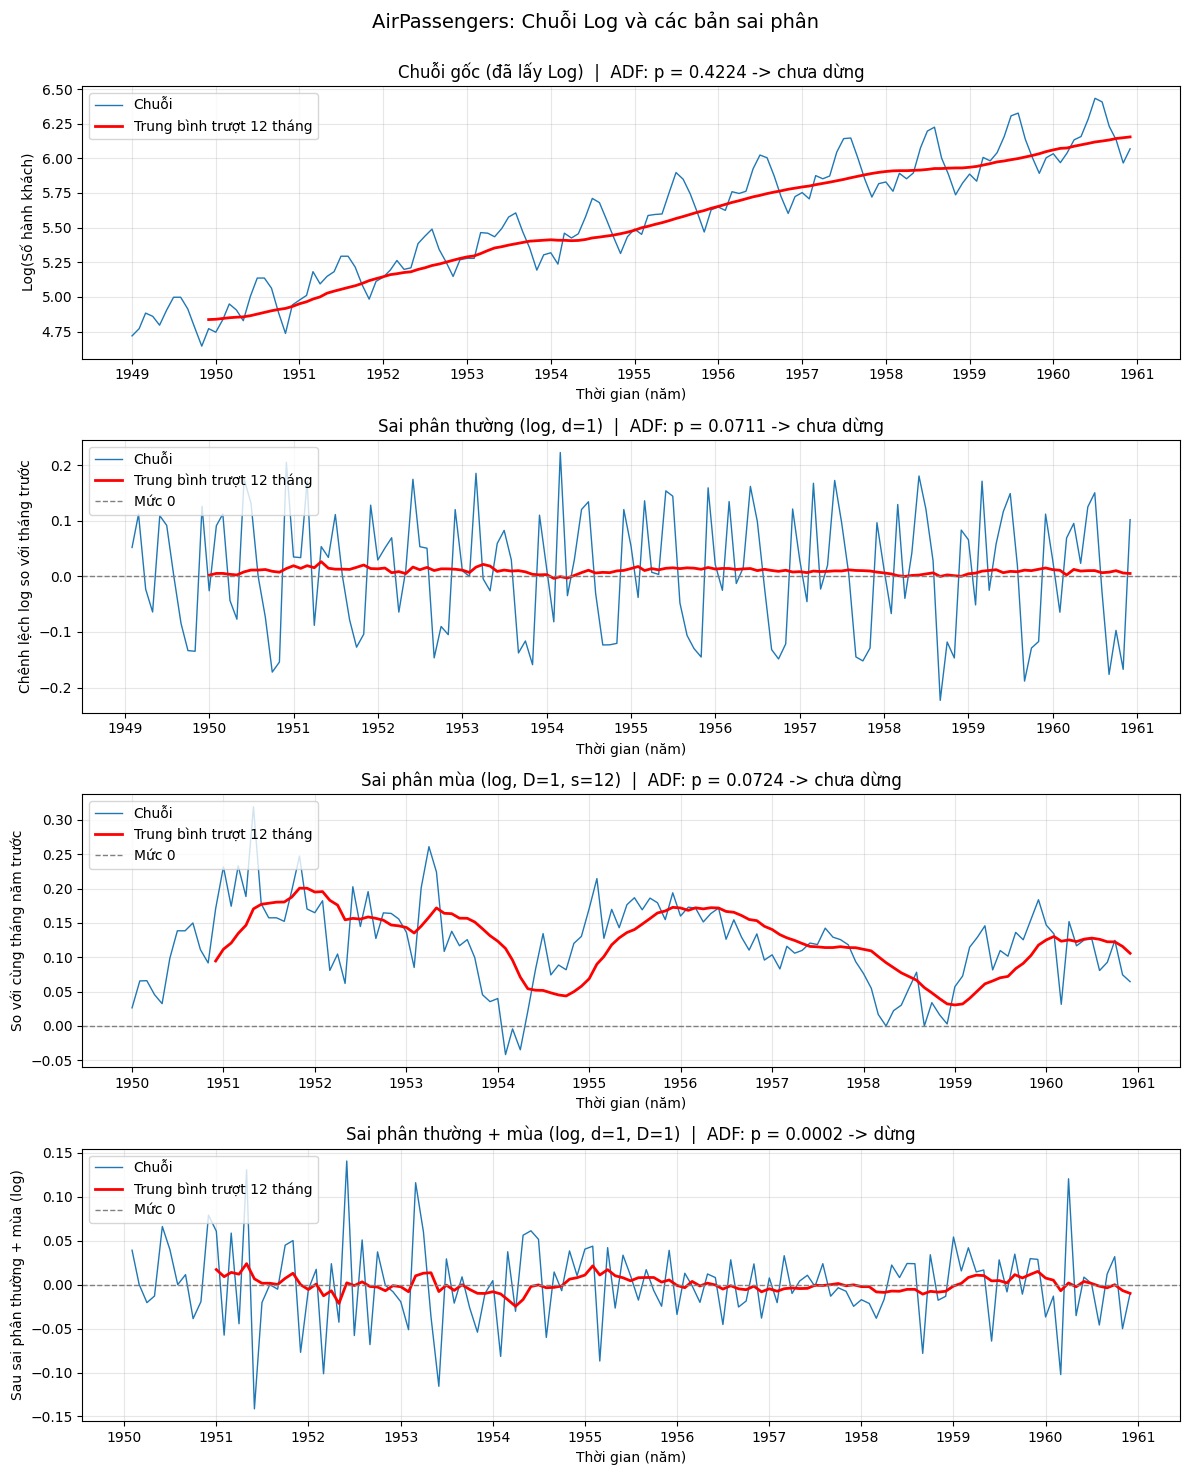

In [26]:
import matplotlib.dates as mdates

def p_adf(x):
    return adfuller(x.dropna(), regression="c", autolag="AIC", result_object=False)[1]

def fmt_p(p):
    return "p < 0.0001" if p < 0.0001 else f"p = {p:.4f}"

cac_chuoi = [
    (ap_log, "Chuỗi gốc (đã lấy Log)",                "Log(Số hành khách)"),
    (d1,     "Sai phân thường (log, d=1)",            "Chênh lệch log so với tháng trước"),
    (s12,    "Sai phân mùa (log, D=1, s=12)",         "So với cùng tháng năm trước"),
    (d1_s12, "Sai phân thường + mùa (log, d=1, D=1)", "Sau sai phân thường + mùa (log)"),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 15))
for i, (ax, (x, ten, ylab)) in enumerate(zip(axes, cac_chuoi)):
    x = x.dropna()
    p = p_adf(x)
    kq = "dừng" if p <= 0.05 else "chưa dừng"

    ax.plot(x, lw=1, label="Chuỗi")
    ax.plot(x.rolling(12).mean(), color="red", lw=2, label="Trung bình trượt 12 tháng")
    if i > 0:
        ax.axhline(0, color="gray", ls="--", lw=1, label="Mức 0")

    ax.set_title(f"{ten}  |  ADF: {fmt_p(p)} -> {kq}")
    ax.set_xlabel("Thời gian (năm)")
    ax.set_ylabel(ylab)
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

fig.suptitle("AirPassengers: Chuỗi Log và các bản sai phân", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

**Nhận xét từng đồ thị:**

1. **Chuỗi gốc sau khi lấy log:** Chuỗi vẫn có xu hướng tăng và biến động theo mùa; trung bình trượt tăng dần theo thời gian. Kiểm định ADF có p-value = 0.4224 > 0.05, nên chưa đủ cơ sở bác bỏ giả thuyết chuỗi có nghiệm đơn vị.

2. **Sai phân thường (d = 1):** Sai phân thường giúp loại bỏ phần lớn xu hướng tăng, nhưng ảnh hưởng mùa vụ vẫn còn. Kiểm định ADF có p-value = 0.0711 > 0.05, nên chưa đủ cơ sở kết luận chuỗi dừng ở mức ý nghĩa 5%.

3. **Sai phân mùa (D = 1, s = 12):** Sai phân mùa làm giảm ảnh hưởng của mẫu lặp lại theo năm. Tuy nhiên, p-value = 0.0724 > 0.05, nên kiểm định ADF chưa cung cấp đủ bằng chứng để kết luận chuỗi dừng ở mức ý nghĩa 5%.

4. **Kết hợp sai phân thường và sai phân mùa (d = 1, D = 1):** Chuỗi dao động quanh mức 0 ổn định hơn. Kiểm định ADF có p-value = 0.0002 < 0.05, cho phép bác bỏ giả thuyết có nghiệm đơn vị. Đây là kết quả phù hợp nhất để tiếp tục phân tích ACF/PACF ở bước tiếp theo.

## 7. Phân tích mùa vụ: vì sao s = 12 và D = 1?

Phần này làm ba việc:
1. **Chứng minh có mùa vụ** bằng số liệu: mỗi tháng có mức cao hay thấp đặc trưng, lặp lại hằng năm.
2. **Tính tay một giá trị sai phân mùa** để hiểu `diff(12)` làm gì.
3. **Thử các chu kỳ s khác nhau** để xem vì sao chọn s = 12.

### 7.1. Mẫu mùa vụ theo tháng

Để thấy mùa vụ, ta tính **độ lệch của mỗi tháng so với trung bình của chính năm đó** (cách này loại bớt ảnh hưởng của xu hướng tăng), rồi lấy trung bình theo tháng trên 12 năm.
- Cột **dương**: tháng đó thường cao hơn mức trung bình năm.
- Cột **âm**: tháng đó thường thấp hơn.
- Nếu không có mùa vụ, các cột sẽ xấp xỉ 0.

T1    -38.5
T2    -45.3
T3    -10.1
T4    -13.2
T5     -8.5
T6     31.4
T7     71.0
T8     70.8
T9     22.1
T10   -13.7
T11   -47.5
T12   -18.5
Name: Passengers, dtype: float64


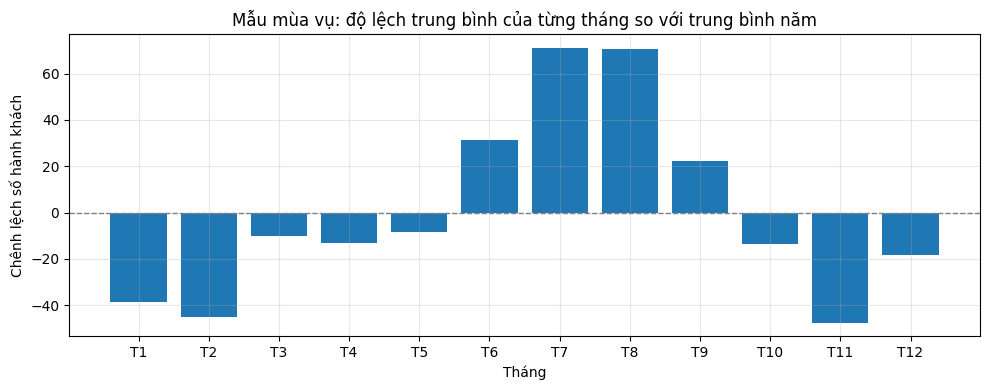

In [27]:
thang = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"]

lech = ap - ap.groupby(ap.index.year).transform("mean")   # độ lệch so với trung bình của chính năm đó
mua = lech.groupby(lech.index.month).mean()
mua.index = thang
print(mua.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(mua.index, mua.values)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set_title("Mẫu mùa vụ: độ lệch trung bình của từng tháng so với trung bình năm")
ax.set_xlabel("Tháng")
ax.set_ylabel("Chênh lệch số hành khách")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:**
- Các tháng **T7 và T8** có cột dương cao nhất (khoảng +70 hành khách so với trung bình năm), tiếp theo là T6 và T9. Các tháng **T11 và T2** có cột âm sâu nhất (khoảng −47 và −45).
- Mùa cao điểm rơi vào mùa hè (T6 đến T9), mùa thấp điểm rơi vào đầu năm và cuối năm.
- Các cột lệch xa mức 0 → **có mùa vụ rõ rệt**. Mẫu này lặp lại mỗi năm, tức chu kỳ **12 tháng**.

### 7.2. Tính tay một giá trị sai phân mùa

Sai phân mùa trên chuỗi log tại tháng 1/1950 bằng log số hành khách tháng 1/1950 trừ log số hành khách tháng 1/1949.

In [28]:
t1 = pd.Timestamp("1950-01-01")
t0 = pd.Timestamp("1949-01-01")

print("Log tháng 1/1950:", ap_log[t1])
print("Log tháng 1/1949:", ap_log[t0])
print("Tính tay:", ap_log[t1] - ap_log[t0])
print("diff(12):", s12[t1])

Log tháng 1/1950: 4.74493212836325
Log tháng 1/1949: 4.718498871295094
Tính tay: 0.026433257068156024
diff(12): 0.026433257068156024


### 7.3. Vì sao chọn s = 12? Thử các chu kỳ khác

Nếu chọn đúng chu kỳ mùa, sai phân mùa sẽ **loại được mẫu lặp**, nên chuỗi còn lại **dao động ít hơn** (độ lệch chuẩn nhỏ). Ta thử nhiều giá trị s sau khi đã sai phân thường (d = 1) và so sánh độ lệch chuẩn.

In [29]:
print("Độ lệch chuẩn của chuỗi sau sai phân thường + sai phân mùa với từng s:")
for s in [4, 6, 9, 11, 12, 13]:
    x = ap_log.diff().diff(s).dropna()
    print(f"s = {s:>2}: số điểm = {len(x):>3} | std = {x.std():.2f}")

Độ lệch chuẩn của chuỗi sau sai phân thường + sai phân mùa với từng s:
s =  4: số điểm = 139 | std = 0.17
s =  6: số điểm = 137 | std = 0.15
s =  9: số điểm = 134 | std = 0.16
s = 11: số điểm = 132 | std = 0.13
s = 12: số điểm = 131 | std = 0.05
s = 13: số điểm = 130 | std = 0.13


**Nhận xét:**

- Độ lệch chuẩn nhỏ nhất ở **s = 12** (std ≈ 0.05). Các chu kỳ khác có độ lệch chuẩn lớn hơn: s = 11 và s = 13 khoảng 0.13, s = 4, 6, 9 khoảng 0.15–0.17.
- Kết quả này phù hợp với mẫu mùa vụ quan sát được ở mục 7.1: dữ liệu có chu kỳ lặp lại theo năm, tương ứng 12 tháng.
- Vì vậy, chọn **s = 12** là phù hợp. Tuy nhiên, độ lệch chuẩn chỉ là bằng chứng bổ sung, không phải tiêu chí duy nhất để xác định chu kỳ mùa vụ.

In [30]:
a = ap_log.diff().diff(12).dropna()
b = ap_log.diff(12).diff().dropna()

print("Hai thứ tự cho cùng kết quả:", np.allclose(a, b))

Hai thứ tự cho cùng kết quả: True


## 8. Kết luận

- **Chu kỳ mùa vụ:** Dữ liệu có tính mùa vụ rõ rệt theo chu kỳ 12 tháng ($s = 12$).
- **Chọn tham số cho SARIMA:** Chọn **$d = 1$** và **$D = 1$** ($s = 12$).
  - *Lý do:*
    - Khi lấy log xong, sai phân thường một mình ($d = 1$) chưa dừng ($p = 0.0711 > 0.05$).
    - Sai phân mùa một mình ($D = 1$) cũng chưa dừng ($p = 0.0724 > 0.05$).
    - Kết hợp cả hai ($d = 1, D = 1$) cho p-value = 0.0002, nhỏ hơn mức ý nghĩa 0.05. Vì vậy, có thể bác bỏ giả thuyết chuỗi có nghiệm đơn vị theo kiểm định ADF. Kết quả này ủng hộ việc lựa chọn phép sai phân kép để tiếp tục phân tích ACF/PACF ở bước tiếp theo.
- **Tính giao hoán:** Thứ tự áp dụng sai phân thường và sai phân mùa không làm thay đổi kết quả chuỗi dừng cuối cùng.
- **Chuyển giao Bước 4:** Chuỗi `d1_s12` (131 điểm sau khi dropna) là dữ liệu đầu vào cho bước 4 để vẽ ACF/PACF và xác định các bậc $p, q, P, Q$.